# LIFE: slewing, resizing and simultaneous resizing with rotation

This notebook extends the first-steps experiments with three independent five-spacecraft reconfigurations near Sun–Earth L2. It keeps the same short Base reference arc, ICRF coordinates, Astrogator spacecraft definitions, two-impulse targeting, executable burn merging and sampled tracking-error diagnostics. Every function and numerical input is included here. No earlier notebook, helper module, saved STK scenario or JWST file is needed.

1. **Slew about a fixed combiner:** tilt the formation by 5° while the combiner's reference position stays fixed relative to Base. SC1–SC4 rotate rigidly about that point. The combiner's attitude changes separately; no attitude dynamics or attitude-control propellant estimate is included.
2. **Formation resizing:** change `L` smoothly from 1,000 m to 2,000 m in six hours. An optional intermediate size and a separate duration for each size change are available.
3. **Resizing and rotation:** use the same size schedule while rotating SC1–SC4 about the fixed LOS. Choose a signed total rotation angle; the default is 90° over the six-hour schedule.

The first Python cells define, check, plot and animate all reference motions. The STK cells then simulate only the selected spacecraft, save their trajectories and Δv, and export a playback bundle for `LIFE_formation_STK_visualisation.ipynb`. Each experiment and burn spacing starts independently from the same initial geometry and epoch; these are alternatives, not consecutive phases.

**Geometry conventions.** Base is an additional freely propagated reference, not the physical combiner. `L` retains the first notebook's meaning: Base-to-vertex distance in the initial pyramid, with opposite collector separation `2L` and adjacent separation `√2 L`. The combiner's desired offset stays fixed relative to Base in all three experiments. During the slew, the collector-plane centre moves around the combiner. During resizing, only SC1–SC4 change their distance from Base; the combiner remains at its initial offset. Combined rotation is about the collector-plane normal, rather than a change of LOS.

Run from the top with Windows, STK 13 Desktop, Astrogator, `agi.stk13`, NumPy, SciPy, Pandas and Matplotlib. Geometry cells run without STK. Numerical defaults are study choices, not LIFE requirements. The embedded rounded seed defines a free reference coast; it does not establish or maintain a periodic halo orbit. No propagated outputs or convergence claims are pre-filled.


## 1. Imports and settings

Edit these settings, restart the kernel and run from the top.

| Setting | Meaning |
|---|---|
| `NUM_SPACECRAFT`, `SPACECRAFT_LABELS` | Select 1–5 followers using the original labels. Base is additional. `None` uses the first N labels. |
| `BURN_SPACINGS_HOURS` | Independent waypoint-spacing experiments. Default `[1, 2]` resolves the six-hour transitions with several coast legs. |
| `SLEW_ANGLE_DEG`, `SLEW_DURATION_HOURS` | Signed LOS tilt and total slew time; default 5° in six hours. |
| `SLEW_AXIS_LOCAL` | Rotation-axis direction in the initial formation axes; default +Y. It must be perpendicular to the initial +Z LOS. |
| `RESIZE_INITIAL_L_M`, `RESIZE_FINAL_L_M` | Initial and final Base-to-collector distances for SC1–SC4. Both resizing experiments use these values. The combiner remains at its initial Base-to-combiner distance, RESIZE_INITIAL_L_M. The slew uses the initial formation size. |
| `RESIZE_INTERMEDIATE_L_M` | `None` uses two sizes. Set a positive value to add one intermediate size. |
| `RESIZE_LEG_HOURS` | One duration per size change. Default `[6.0]`; for an intermediate size use e.g. `[5.0, 3.0]`. These are durations, not absolute times. |
| `COMBINED_ROTATION_DEG` | Signed total rotation about the LOS during the complete resize schedule; default +90°. |
| `COMBINED_INITIAL_PHASE_DEG` | Initial collector roll in the combined experiment only. Zero matches the resize-only initial geometry. |
| `SAMPLE_S` | Error-report sampling cadence; independent of burn spacing and STK integrator accuracy. |
| `START_OFFSET_DAYS` | Release delay along the embedded Base coast. Large delays need reference-orbit checks. |

Each size leg uses a quintic profile with zero size rate and acceleration at both ends. An intermediate size is reached at its exact knot time and has zero size rate there, without an added dwell. The combined rotation uses one smooth angular profile over the full schedule; it need not stop at the intermediate size. Changing `RESIZE_LEG_HOURS` therefore also changes the combined angular speed. Both operations start and finish at rest relative to Base in ICRF axes.

The slew and both resizing experiments keep the combiner's desired offset fixed relative to Base. Actual motion coasts between corrected waypoints and may deviate slightly. The combiner's reported translational Δv is maintenance of that offset; its attitude-change cost is separate. No spacecraft is held fixed in absolute inertial space.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from functools import lru_cache
from itertools import combinations
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.spatial.transform import Rotation
from scipy.integrate import trapezoid

NUM_SPACECRAFT = 5
SPACECRAFT_LABELS = None               # Example: ['SC1', 'combiner'] with NUM_SPACECRAFT = 2.
BURN_SPACINGS_HOURS = [1.0, 2.0]
LOS_START = np.array([0.0, 0.0, 1.0])
SLEW_ANGLE_DEG = 5.0
SLEW_DURATION_HOURS = 6.0
SLEW_AXIS_LOCAL = np.array([0.0, 1.0, 0.0])

RESIZE_INITIAL_L_M = 1000.0
RESIZE_INTERMEDIATE_L_M = None         # Example: 1500.0, with RESIZE_LEG_HOURS = [5.0, 3.0].
RESIZE_FINAL_L_M = 2000.0
RESIZE_LEG_HOURS = [6.0]
COMBINED_ROTATION_DEG = 90.0           # Negative values reverse the rotation.
COMBINED_INITIAL_PHASE_DEG = 0.0

START_OFFSET_DAYS = 0.0
SAMPLE_S = 300.0
POSITION_TOL_M = 0.10
VELOCITY_TOL_MPS = 1e-6
DC_PERTURBATION_MPS = 1e-4
DC_MAX_STEP_MPS = 0.1
DC_MAX_ITERATIONS = 30
RUN_SLEW = True
RUN_RESIZING = True
RUN_RESIZING_ROTATION = True
STOP_AT_END = True                    # All three smooth references already end at rest.
ANIMATE_REFERENCES = True
ANIMATE_ACTUAL = True
ANIMATION_FRAMES = 101
ANIMATION_INTERVAL_MS = 70
SAVE_SCENARIO = True

PROPAGATOR_NAME = 'Earth Default High Fidelity v13'
BASE_SEED_UTCG = '6 Oct 2022 07:10:00.000'
# Rounded Earth-centred ICRF state reused from the first-steps notebook [m, m/s].
BASE_SEED_R_M = np.array([1.15803168e9, 9.39831792e7, 4.32308211e8])
BASE_SEED_V_MPS = np.array([-124.13911218, 510.44906145, 237.63841329])
DRY_MASS_KG = 50.0
FUEL_MASS_KG = 50.0
AREA_M2 = 2.0
CR = 1.0
CD = 2.2

plt.rcParams.update({'font.size': 11, 'figure.figsize': (10, 5),
                     'animation.embed_limit': 100.0})


## 2. Validate the choices and print the run plan

Validate sizes, axis directions and time intervals before creating STK objects. Every resize knot is inserted into the regular waypoint grid, so an intermediate size cannot be skipped when its time is not a multiple of the requested burn spacing. The printed leg count includes those extra waypoints. The listed spacing is therefore the requested regular spacing; individual legs can be shorter.

All cases use the same Base trajectory and release epoch. Results are saved after each successful spacecraft case. Astrogator reruns earlier segments as its mission sequence grows, so runtime can increase faster than the number of legs.


In [2]:
LABELS = ['SC1', 'SC2', 'SC3', 'SC4', 'combiner']
if not isinstance(NUM_SPACECRAFT, int) or isinstance(NUM_SPACECRAFT, bool) or not 1 <= NUM_SPACECRAFT <= len(LABELS):
    raise ValueError('NUM_SPACECRAFT must be an integer from 1 to 5.')
SELECTED_LABELS = LABELS[:NUM_SPACECRAFT] if SPACECRAFT_LABELS is None else list(SPACECRAFT_LABELS)
if (len(SELECTED_LABELS) != NUM_SPACECRAFT or len(set(SELECTED_LABELS)) != NUM_SPACECRAFT
        or any(label not in LABELS for label in SELECTED_LABELS)):
    raise ValueError('Choose NUM_SPACECRAFT different labels from ' + str(LABELS))
SELECTED_VERTICES = [LABELS.index(label) for label in SELECTED_LABELS]

def positive_list(values, name):
    if not values or any(not np.isfinite(v) or v <= 0 for v in values):
        raise ValueError(name + ' must contain positive, finite numbers.')
    return sorted(set(float(v) for v in values))

BURN_SPACINGS_HOURS = positive_list(BURN_SPACINGS_HOURS, 'BURN_SPACINGS_HOURS')
for name in ['RESIZE_INITIAL_L_M', 'RESIZE_FINAL_L_M', 'SLEW_DURATION_HOURS',
             'SAMPLE_S', 'POSITION_TOL_M', 'VELOCITY_TOL_MPS',
             'DC_PERTURBATION_MPS', 'DC_MAX_STEP_MPS', 'DRY_MASS_KG']:
    if not np.isfinite(globals()[name]) or globals()[name] <= 0:
        raise ValueError(name + ' must be positive and finite.')
if not np.isfinite(START_OFFSET_DAYS) or START_OFFSET_DAYS < 0:
    raise ValueError('START_OFFSET_DAYS must be finite and non-negative.')
if min(BURN_SPACINGS_HOURS)*3600 < 1:
    raise ValueError('Burn spacings must be at least one second.')
if ANIMATION_FRAMES < 2 or DC_MAX_ITERATIONS < 1:
    raise ValueError('Choose at least two animation frames and one targeter iteration.')
if not any([RUN_SLEW, RUN_RESIZING, RUN_RESIZING_ROTATION]):
    raise ValueError('Enable at least one experiment.')
if any(not np.isfinite(v) or v < 0 for v in [FUEL_MASS_KG, AREA_M2, CR, CD]):
    raise ValueError('Mass, area and optical/aerodynamic coefficients must be non-negative.')
if BASE_SEED_R_M.shape != (3,) or BASE_SEED_V_MPS.shape != (3,) or not np.isfinite(np.r_[BASE_SEED_R_M, BASE_SEED_V_MPS]).all():
    raise ValueError('Base requires two finite three-component vectors.')


for name in ['LOS_START', 'SLEW_AXIS_LOCAL']:
    value = np.asarray(globals()[name], dtype=float)
    if value.shape != (3,) or not np.isfinite(value).all() or np.linalg.norm(value) < 1e-14:
        raise ValueError(name + ' must be a finite nonzero three-component vector.')
    globals()[name] = value
if abs(SLEW_AXIS_LOCAL[2])/np.linalg.norm(SLEW_AXIS_LOCAL) > 1e-12:
    raise ValueError('SLEW_AXIS_LOCAL must be perpendicular to local +Z.')
if not np.isfinite(SLEW_ANGLE_DEG) or abs(SLEW_ANGLE_DEG) >= 180:
    raise ValueError('Choose a finite slew angle strictly between -180 and +180 degrees.')
for name in ['COMBINED_ROTATION_DEG', 'COMBINED_INITIAL_PHASE_DEG']:
    if not np.isfinite(globals()[name]):
        raise ValueError(name + ' must be finite.')
RESIZE_SIZES_M = [float(RESIZE_INITIAL_L_M)]
if RESIZE_INTERMEDIATE_L_M is not None:
    if not np.isfinite(RESIZE_INTERMEDIATE_L_M) or RESIZE_INTERMEDIATE_L_M <= 0:
        raise ValueError('Intermediate L must be positive or None.')
    RESIZE_SIZES_M.append(float(RESIZE_INTERMEDIATE_L_M))
RESIZE_SIZES_M.append(float(RESIZE_FINAL_L_M))
if len(RESIZE_LEG_HOURS) != len(RESIZE_SIZES_M)-1:
    raise ValueError('Use one resize-leg duration per size change: [6.0], or e.g. [5.0, 3.0].')
if any(not np.isfinite(x) or x <= 0 for x in RESIZE_LEG_HOURS):
    raise ValueError('Every resize-leg duration must be positive and finite.')
if not isinstance(ANIMATION_FRAMES, int) or not isinstance(DC_MAX_ITERATIONS, int):
    raise ValueError('Animation frames and targeter iterations must be integers.')

DAY_S = 86400.0
L_M = float(RESIZE_INITIAL_L_M)
RESIZE_KNOTS_S = np.r_[0.0, np.cumsum(RESIZE_LEG_HOURS)*3600.0]
RESIZE_DURATION_S = float(RESIZE_KNOTS_S[-1])
SLEW_DURATION_S = SLEW_DURATION_HOURS*3600.0
MAX_L_M = max(RESIZE_SIZES_M)
OPERATIONS = [('Slew about combiner', RUN_SLEW, SLEW_DURATION_S),
              ('Formation resizing', RUN_RESIZING, RESIZE_DURATION_S),
              ('Resizing and rotation', RUN_RESIZING_ROTATION, RESIZE_DURATION_S)]

def waypoint_times(duration_s, spacing_s, operation=None):
    if duration_s <= 0 or spacing_s <= 0:
        raise ValueError('Duration and spacing must be positive.')
    times = np.arange(0.0, duration_s, spacing_s)
    knots = RESIZE_KNOTS_S if operation in ['Formation resizing', 'Resizing and rotation'] else np.array([0.0, duration_s])
    # Prefer exact schedule knots over practically coincident regular grid points.
    times = np.array([t for t in times if np.all(np.abs(knots-t) > 1e-7)])
    return np.sort(np.r_[times, knots])

plan = []
for operation, enabled, duration in OPERATIONS:
    if enabled:
        for spacing_hr in BURN_SPACINGS_HOURS:
            times = waypoint_times(duration, spacing_hr*3600, operation)
            plan.append(dict(operation=operation, duration_days=duration/DAY_S,
                             spacing_hours=spacing_hr, spacecraft=NUM_SPACECRAFT,
                             targeted_legs=NUM_SPACECRAFT*(len(times)-1)))
plan = pd.DataFrame(plan)
RUN_TAG = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT = Path.cwd() / 'results' / ('LIFE_second_steps_' + RUN_TAG)
OUT.mkdir(parents=True, exist_ok=False)
plan.to_csv(OUT/'run_plan.csv', index=False)
display(plan)
print('Simulated followers:', SELECTED_LABELS, '| Base is additional.')
print('Resize sizes [m]:', RESIZE_SIZES_M, '| knot times [h]:', RESIZE_KNOTS_S/3600)
print('Total targeted legs:', int(plan.targeted_legs.sum()))
print('Outputs:', OUT)


,operation,duration_days,spacing_hours,spacecraft,targeted_legs
0,Slew about combiner,0.25,1.0,5,30
1,Slew about combiner,0.25,2.0,5,15
2,Formation resizing,0.25,1.0,5,30
3,Formation resizing,0.25,2.0,5,15
4,Resizing and rotation,0.25,1.0,5,30
5,Resizing and rotation,0.25,2.0,5,15


Simulated followers: ['SC1', 'SC2', 'SC3', 'SC4', 'combiner'] | Base is additional.
Resize sizes [m]: [1000.0, 2000.0] | knot times [h]: [0. 6.]
Total targeted legs: 135
Outputs: /Users/pedroleonardo/Desktop/LIFE/Working/Own-Code/Experiments/results/LIFE_second_steps_20261110_234638_841213


## 3. Define the oriented formation and slew pivot

Keep SC1–SC4 at `(±L,0,0)` and `(0,±L,0)`, and combiner at `(0,0,+L)` before orientation. Initial +Z follows `LOS_START`; projected ICRF +X defines the initial roll, as in the first notebook. `SLEW_AXIS_LOCAL` is expressed in these initial axes and is then converted to ICRF.

For slewing, freeze the initial combiner offset `c`. Rotate the other vertices about `c`, not about Base. The collector-plane centre moves to `c − L n(t)`, where `n(t)` is the new LOS, while every inter-spacecraft distance remains unchanged. This differs intentionally from the earlier Base-centred re-pointing.


In [3]:
VERTICES = L_M * np.array([[1,0,0], [-1,0,0], [0,1,0], [0,-1,0], [0,0,1]], float)
PAIRS = list(combinations(range(len(LABELS)), 2))

def unit(vector):
    vector = np.asarray(vector, dtype=float)
    length = np.linalg.norm(vector)
    if length < 1e-14:
        raise ValueError('A direction must be nonzero.')
    return vector / length

def initial_orientation(los):
    z = unit(los)
    seed = np.array([1.0, 0.0, 0.0])
    if abs(np.dot(seed, z)) > 0.95:
        seed = np.array([0.0, 1.0, 0.0])
    x = unit(seed - np.dot(seed, z) * z)
    y = np.cross(z, x)
    return np.column_stack([x, y, z])

Q0 = initial_orientation(LOS_START)

SLEW_AXIS = unit(Q0 @ unit(SLEW_AXIS_LOCAL))
SLEW_ANGLE = np.deg2rad(SLEW_ANGLE_DEG)
LOS_END = Rotation.from_rotvec(SLEW_AXIS*SLEW_ANGLE).apply(unit(LOS_START))
COMBINER_POSITION_M = (VERTICES @ Q0.T)[LABELS.index('combiner')]
# Slewing about the combiner can move vertices farther from Base than L.
DISPLAY_RADIUS_M = max(MAX_L_M, (1 + np.sqrt(2))*L_M)
print('Initial L:', L_M, 'm; opposite collector baseline:', 2*L_M, 'm')
print('Slew LOS:', unit(LOS_START), 'to', LOS_END)


Initial L: 1000.0 m; opposite collector baseline: 2000.0 m
Slew LOS: [0. 0. 1.] to [0.08715574 0.         0.9961947 ]


## 4. Desired positions and velocities

`reference(t, operation)` returns all five desired offsets in metres and relative velocities in m/s, with ICRF axis directions.

For SC1–SC4, resizing uses p = L(t) q and v = Ldot(t) q. Simultaneous resizing and rotation uses v = Ldot(t) Rq + ω × p, including both radial and tangential motion. In both experiments, the combiner instead keeps its initial reference position and has zero reference velocity relative to Base.

The quintic law `s(u) = 10u³ − 15u⁴ + 6u⁵` gives zero rate and acceleration at its endpoints. Resize legs use it separately. Rotation in the combined case uses it over the complete schedule, from `COMBINED_INITIAL_PHASE_DEG` through an additional `COMBINED_ROTATION_DEG`. The angle is an explicit finite manoeuvre, not the constant 28-day spin of the first notebook. All reference positions are held at their endpoints outside the manoeuvre interval.


In [4]:
def smooth_step(t_s, duration_s):
    u = np.clip(float(t_s)/duration_s, 0.0, 1.0)
    s = 10*u**3 - 15*u**4 + 6*u**5
    ds = (30*u**2 - 60*u**3 + 30*u**4)/duration_s
    return s, ds

def resize_state(t_s):
    t = float(t_s)
    if t <= 0:
        return RESIZE_SIZES_M[0], 0.0
    if t >= RESIZE_DURATION_S:
        return RESIZE_SIZES_M[-1], 0.0
    leg = min(int(np.searchsorted(RESIZE_KNOTS_S, t, side='right')-1), len(RESIZE_SIZES_M)-2)
    ta, tb = RESIZE_KNOTS_S[leg:leg+2]
    s, ds = smooth_step(t-ta, tb-ta)
    change = RESIZE_SIZES_M[leg+1]-RESIZE_SIZES_M[leg]
    return RESIZE_SIZES_M[leg]+change*s, change*ds

def reference(t_s, operation='Slew about combiner'):
    t = float(t_s)
    if operation == 'Slew about combiner':
        s, ds = smooth_step(t, SLEW_DURATION_S)
        turn = Rotation.from_rotvec(SLEW_AXIS*SLEW_ANGLE*s).as_matrix()
        initial = VERTICES @ Q0.T
        position_m = COMBINER_POSITION_M + (initial-COMBINER_POSITION_M) @ turn.T
        omega = SLEW_AXIS*SLEW_ANGLE*ds
        velocity_mps = np.cross(omega, position_m-COMBINER_POSITION_M)
    elif operation in ['Formation resizing', 'Resizing and rotation']:
        length, rate = resize_state(t)
        turn, omega = np.eye(3), np.zeros(3)
        if operation == 'Resizing and rotation':
            s, ds = smooth_step(t, RESIZE_DURATION_S)
            angle = np.deg2rad(COMBINED_INITIAL_PHASE_DEG + COMBINED_ROTATION_DEG*s)
            turn = Rotation.from_rotvec(unit(LOS_START)*angle).as_matrix()
            omega = unit(LOS_START)*np.deg2rad(COMBINED_ROTATION_DEG)*ds
        directions = (VERTICES/L_M) @ (turn @ Q0).T
        position_m = length*directions
        velocity_mps = rate*directions + np.cross(omega, position_m)
    else:
        raise ValueError(operation)
    
    if operation in ['Formation resizing', 'Resizing and rotation']:
        combiner_vertex = LABELS.index('combiner')
        position_m[combiner_vertex] = COMBINER_POSITION_M
        velocity_mps[combiner_vertex] = 0.0

    return position_m, velocity_mps


## 5. Verify the reference geometry and velocities

Check rigid inter-spacecraft distances during slewing; the fixed combiner position in all three experiments; collector radii and pair distances consistent with a fixed combiner during resizing; the requested final LOS and rotation phase; zero start/end velocities; exact optional intermediate sizes; and analytic velocities against finite differences inside the manoeuvres. These checks use only the geometric reference, not STK propagation.


In [5]:
def pair_distances(points):
    return np.array([np.linalg.norm(points[i]-points[j]) for i,j in PAIRS])

combiner_vertex = LABELS.index('combiner')
reference_distances = pair_distances(VERTICES)
checks = []
for operation, enabled, duration in OPERATIONS:
    for t in np.linspace(0, duration, 41):
        p, velocity = reference(t, operation)
        scale = 1.0 if operation == 'Slew about combiner' else resize_state(t)[0]/L_M
        expected_vertices = VERTICES.copy()
        expected_vertices[:4] *= scale   # Resize only SC1–SC4.
        np.testing.assert_allclose(pair_distances(p), pair_distances(expected_vertices),rtol=1e-12, atol=1e-8)
        if operation == 'Slew about combiner':
            np.testing.assert_allclose(p[combiner_vertex], COMBINER_POSITION_M, atol=1e-10)
            np.testing.assert_allclose(velocity[combiner_vertex], 0, atol=1e-12)
        else:
            np.testing.assert_allclose(np.linalg.norm(p[:4], axis=1), resize_state(t)[0], atol=1e-8)
            np.testing.assert_allclose(p[combiner_vertex], COMBINER_POSITION_M, atol=1e-10)
            np.testing.assert_allclose(velocity[combiner_vertex], 0.0, atol=1e-12)
        if 1 < t < duration-1:
            h = min(0.05, np.min(np.diff(RESIZE_KNOTS_S))/10000, duration/10000)
            fd = (reference(t+h,operation)[0]-reference(t-h,operation)[0])/(2*h)
            np.testing.assert_allclose(fd, velocity, rtol=2e-6, atol=1e-7)
    for t in [0.0, duration]:
        np.testing.assert_allclose(reference(t,operation)[1], 0, atol=1e-12)
    checks.append(dict(operation=operation, geometry_and_velocity_checks='passed'))
p, _ = reference(SLEW_DURATION_S, 'Slew about combiner')
np.testing.assert_allclose(unit(p[combiner_vertex]-p[:4].mean(axis=0)), LOS_END, atol=1e-12)
for t, size in zip(RESIZE_KNOTS_S, RESIZE_SIZES_M):
    np.testing.assert_allclose(resize_state(t), [size, 0.0], atol=1e-10)
angle = np.deg2rad(COMBINED_INITIAL_PHASE_DEG+COMBINED_ROTATION_DEG)
expected = Rotation.from_rotvec(unit(LOS_START)*angle).apply(Q0[:,0])*RESIZE_FINAL_L_M
np.testing.assert_allclose(reference(RESIZE_DURATION_S,'Resizing and rotation')[0][0], expected, atol=1e-8)
display(pd.DataFrame(checks))


,operation,geometry_and_velocity_checks
0,Slew about combiner,passed
1,Formation resizing,passed
2,Resizing and rotation,passed


### Reference paths and exports

Plot all three desired motions and export the complete five-vertex positions and velocities. These are reference paths with no dynamical tracking error. The slew plot is Base-centred even though the rigid rotation pivot is the combiner.


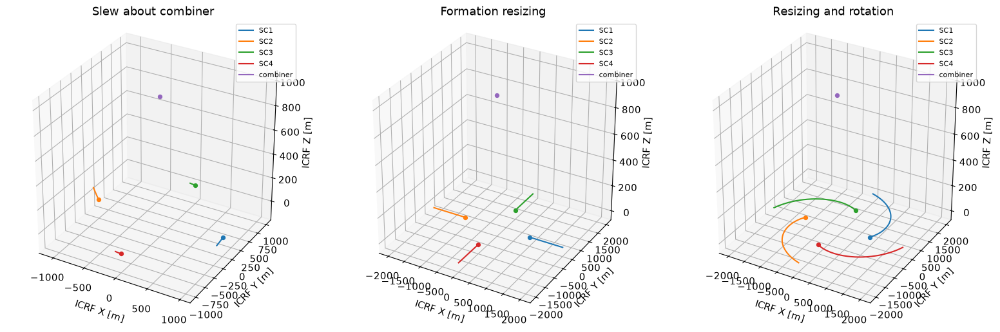

In [6]:
fig = plt.figure(figsize=(16, 5))
for panel, (operation, duration) in enumerate([(op, duration) for op, enabled, duration in OPERATIONS], 1):
    times = np.linspace(0, duration, 181)
    states = [reference(t, operation) for t in times]
    positions = np.array([s[0] for s in states])
    velocities = np.array([s[1] for s in states])
    ax = fig.add_subplot(1, 3, panel, projection='3d')
    rows = []
    for j, label in enumerate(LABELS):
        ax.plot(*positions[:,j,:].T, label=label)
        ax.scatter(*positions[0,j,:], s=18)
        for k, t in enumerate(times):
            rows.append([t, label, *positions[k,j], *velocities[k,j]])
    ax.set(xlabel='ICRF X [m]', ylabel='ICRF Y [m]', zlabel='ICRF Z [m]', title=operation)
    ax.set_box_aspect((1,1,1))
    ax.legend(fontsize=8)
    pd.DataFrame(rows, columns=['elapsed_s','vertex','x_m','y_m','z_m','vx_mps','vy_mps','vz_mps']).to_csv(OUT/f'reference_{operation}.csv', index=False)
fig.tight_layout()
fig.savefig(OUT/'reference_geometry.png', dpi=180, bbox_inches='tight')
plt.show()


## 6. Animate the desired reconfigurations

Animate and save each full reference operation as an HTML movie. Filled red points mark selected followers; hollow grey points remain reference-only. The eight edges follow the full desired pyramid. Base is at the origin. During the slew, the combiner stays at its initial offset and the base plane moves around it. These movies do not estimate Δv.


In [7]:
EDGES = [(i,j) for i,j in PAIRS
         if np.isclose(np.linalg.norm(VERTICES[i]-VERTICES[j]), np.sqrt(2)*L_M)]

def show_animation(animation, figure, filename):
    html = animation.to_jshtml()
    (OUT/filename).write_text(html, encoding='utf-8')
    plt.close(figure)
    display(HTML(html))

def animate_reference(operation):
    duration = next(duration for op, enabled, duration in OPERATIONS if op == operation)
    times = np.linspace(0, duration, ANIMATION_FRAMES)
    fig = plt.figure(figsize=(7,6))
    ax = fig.add_subplot(projection='3d')
    limit = 1.2*DISPLAY_RADIUS_M
    ax.set(xlim=(-limit,limit), ylim=(-limit,limit), zlim=(-limit,limit),
           xlabel='ICRF X [m]', ylabel='ICRF Y [m]', zlabel='ICRF Z [m]')
    ax.set_box_aspect((1,1,1))
    lines = [ax.plot([], [], [], color='steelblue', alpha=.65)[0] for _ in EDGES]
    points = ax.scatter([], [], [], facecolors='none', edgecolors='grey', label='Reference vertices')
    selected = ax.scatter([], [], [], color='darkred', label='Selected followers')
    ax.scatter(0,0,0,color='black',marker='+',label='Base')
    texts = [ax.text(0,0,0,label) for label in LABELS]
    ax.legend(fontsize=8)

    def draw_frame(k):
        p, _ = reference(times[k], operation)
        for line, (i,j) in zip(lines, EDGES):
            line.set_data_3d(*p[[i,j]].T)
        points._offsets3d = tuple(p.T)
        selected._offsets3d = tuple(p[SELECTED_VERTICES].T)
        for text, xyz in zip(texts, p):
            text.set_position((xyz[0],xyz[1]))
            text.set_3d_properties(xyz[2], zdir='z')
        ax.set_title(f'{operation}: {times[k]/DAY_S:.2f} days')
        return lines

    animation = FuncAnimation(fig, draw_frame, frames=len(times), interval=ANIMATION_INTERVAL_MS)
    show_animation(animation, fig, f'reference_{operation}_animation.html')

if ANIMATE_REFERENCES:
    for operation, enabled, duration in OPERATIONS:
        animate_reference(operation)


## 7. Executable burn accounting

Keep the first notebook's vector merging: an arrival and the following departure at the same epoch are charged as the norm of their vector sum. Summing their individual norms would overestimate executable Δv. Both the raw and merged impulses are saved. Resize knots are already included by `waypoint_times()` in section 2.


In [ ]:
def merge_burns(raw):
    if raw.empty:
        return pd.DataFrame(columns=['elapsed_s','dvx_mps','dvy_mps','dvz_mps','dv_mps','cumulative_mps'])
    grouped = raw.groupby('elapsed_s', sort=True)[['dvx_mps','dvy_mps','dvz_mps']].sum().reset_index()
    grouped['dv_mps'] = np.linalg.norm(grouped[['dvx_mps','dvy_mps','dvz_mps']], axis=1)
    grouped['cumulative_mps'] = grouped['dv_mps'].cumsum()
    return grouped

assert waypoint_times(10, 4).tolist() == [0,4,8,10]
trial = pd.DataFrame([[1,1,0,0], [1,-1,0,0]], columns=['elapsed_s','dvx_mps','dvy_mps','dvz_mps'])
assert merge_burns(trial)['dv_mps'].sum() == 0


## 8. Record the settings

Save a machine-readable description before propagation. Keep the embedded state epoch separate from the follower release epoch. The actual force-model component and its installed attributes are recorded after starting STK. No Δv is inferred from a reference speed or an animation.


In [ ]:
setting_names = [name for name in list(globals()) if name.isupper() and name not in
                 ['OUT', 'VERTICES', 'PAIRS', 'EDGES', 'Q0', 'SLEW_AXIS']]
settings = {'created_utc': datetime.now(timezone.utc).isoformat(), 'status': 'running'}
for name in setting_names:
    value = globals()[name]
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (str, int, float, bool, list, type(None))):
        settings[name] = value
settings['base_seed_provenance'] = 'Rounded Earth-ICRF state printed in supplied LIFE_formation_first_steps.ipynb, cell 22'
settings['base_model'] = 'Free coast from embedded state; explicit common spacecraft properties; no halo-maintenance manoeuvres'
(OUT/'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
completed_cases = []

settings['slew_pivot'] = 'Initial combiner offset, fixed relative to Base'
settings['resize_pivot'] = ('SC1–SC4 resize about Base; combiner stays at its initial offset')
settings['attitude_cost_included'] = False
(OUT/'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')


## 9. Start a fresh STK 13 Desktop scenario

Launch a new application and create a new scenario from the embedded seed epoch, covering the longest enabled operation plus release delay and one hour of margin. No previous application is attached to or closed. All Object Model distances and small distances are metres, time is seconds, and `EpSec` is seconds since the scenario epoch. Geometry-only execution ends here on systems without STK.


In [ ]:
if os.name != 'nt':
    raise RuntimeError('The following cells require Windows STK 13 Desktop and Astrogator.')
from agi.stk13.stkdesktop import STKDesktop
from agi.stk13.stkobjects import AgESTKObjectType, AgEVePropagatorType
from agi.stk13.stkobjects.astrogator import (
    AgEVASegmentType, AgEVAElementType, AgEVAManeuverType,
    AgEVAAttitudeControl, AgEVAControlManeuver, AgEVATargetSeqAction,
    AgEVAProfileMode,
)
stk = STKDesktop.StartApplication(visible=True, userControl=True)
root = stk.Root
root.NewScenario('LIFE_SecondSteps_' + RUN_TAG)
scenario = root.CurrentScenario
root.UnitPreferences.ResetUnits()
root.UnitPreferences.SetCurrentUnit('DateFormat', 'UTCG')
scenario.Epoch = BASE_SEED_UTCG
for dimension, value in [('Distance','m'), ('SmallDistance','m'), ('Time','sec'),
                         ('DateFormat','EpSec'), ('Mass','kg')]:
    root.UnitPreferences.SetCurrentUnit(dimension, value)
SEED_EPOCH = float(root.ConversionUtility.ConvertDate('UTCG', 'EpSec', BASE_SEED_UTCG))
T0 = SEED_EPOCH + START_OFFSET_DAYS*DAY_S
REQUIRED_DURATION_S = float((plan.duration_days.max())*DAY_S)
BASE_END_EPOCH = T0 + REQUIRED_DURATION_S + 3600.0
SCENARIO_END_EPOCH = BASE_END_EPOCH
scenario.SetTimePeriod(str(SEED_EPOCH), str(SCENARIO_END_EPOCH))
FRAME = 'CentralBody/Earth ICRF'
print('Fresh scenario:', scenario.InstanceName)
print('Follower release UTC:', root.ConversionUtility.ConvertDate('EpSec','UTCG',str(T0)))


## 10. Create Astrogator spacecraft and coasts from explicit inputs

Insert new satellites, clear their default mission sequences, and define their initial Cartesian states. The coast uses `Earth Default High Fidelity v13`, the named propagator recorded in the earlier experiment. The notebook does not copy a coast from another spacecraft or switch silently to a two-body model. It stops if the selected component is unavailable.

Mass is held fixed during impulses. The explicit 50 kg dry mass, 50 kg fuel and 2 m² areas reproduce the follower properties printed in the earlier notebook. Base uses these same explicit values for a matched reference; its historical physical parameters were not recorded in the supplied outputs. The installed propagator attributes are saved for inspection, including numerical-integrator and force-model settings exposed by STK. Reporting cadence does not set integrator accuracy.

**Embedded Base state.** The seed in section 1 is the Earth-centred ICRF state printed at 6 October 2022, 07:10 UTC in the earlier notebook. Its printed position has limited precision (metre-to-several-metre level). Propagating this state gives an independent reference arc near the same location, but cannot reproduce the original ephemeris bit for bit. A full-precision original Base state is not embedded in these notebooks. There is no reconstruction of the earlier crossing-targeted Base mission or a new halo orbit optimisation here. Base coasts without impulses; long arcs and large release delays need inspection for departure from the L2 neighbourhood. Replacing the seed with a full-precision state is sufficient to change the starting orbit without introducing a file dependency.


In [ ]:
def new_experiment(label, position_m, velocity_mps, start_epoch=None, frame=FRAME):
    if start_epoch is None:
        start_epoch = T0
    name = 'SS_' + label
    sat = scenario.Children.New(AgESTKObjectType.eSatellite, name)
    sat.SetPropagatorType(AgEVePropagatorType.ePropagatorAstrogator)
    driver = sat.Propagator
    driver.Options.EnableTrajectorySegmentColors = False
    driver.Options.DrawTrajectoryIn3D = False
    driver.Options.DrawTrajectoryIn2D = False
    driver.MainSequence.RemoveAll()
    initial = driver.MainSequence.Insert(AgEVASegmentType.eVASegmentTypeInitialState, 'Initial', '-')
    initial.CoordSystemName = frame
    initial.OrbitEpoch = str(float(start_epoch))
    initial.SetElementType(AgEVAElementType.eVAElementTypeCartesian)
    for attr, value in zip(['X','Y','Z','Vx','Vy','Vz'], np.r_[position_m,velocity_mps]):
        setattr(initial.Element, attr, float(value))
    properties = dict(Cd=CD, Cr=CR, DryMass=DRY_MASS_KG, DragArea=AREA_M2,
                      K1=1.0, K2=1.0, RadiationPressureArea=AREA_M2,
                      Ck=1.0, SolarRadiationPressureArea=AREA_M2)
    for attr, value in properties.items():
        setattr(initial.SpacecraftParameters, attr, float(value))
    for attr, value in dict(FuelMass=FUEL_MASS_KG, FuelDensity=1000.0,
                            TankPressure=5000.0, TankTemperature=293.15).items():
        setattr(initial.FuelTank, attr, value)
    return sat, driver

def add_coast(sequence, name, duration_s):
    segment = sequence.Insert(AgEVASegmentType.eVASegmentTypePropagate, name, '-')
    segment.PropagatorName = PROPAGATOR_NAME
    stops = segment.StoppingConditions
    if 'Duration' not in [stops.Item(i).Name for i in range(stops.Count)]:
        stops.Add('Duration')
    for i in range(stops.Count-1, -1, -1):
        if stops.Item(i).Name != 'Duration':
            stops.Remove(i)
    duration = stops.Item('Duration')
    duration.Active = True
    duration.Properties.Trip = float(duration_s)
    duration.Properties.Tolerance = 1e-6
    duration.Properties.Sequence = 'Stop'
    segment.MinPropagationTime = 0.0
    segment.EnableMaxPropagationTime = True
    segment.MaxPropagationTime = float(duration_s) + 60.0
    return segment

root.ExecuteCommand('Units_SetConnect / Distance Meter Time Second Date GregorianUTC')

# GetValue returns the actual installed component attributes, not just its name.
component_info = root.ExecuteCommand(f'ComponentBrowser_RM */ GetValue "Propagators" "{PROPAGATOR_NAME}"')
component_text = '\n'.join(component_info.Item(i) for i in range(component_info.Count))
(OUT/'propagator_component.txt').write_text(component_text, encoding='utf-8')
print('Propagator:', PROPAGATOR_NAME)
print('Component definition saved to propagator_component.txt; inspect it alongside the STK Component Browser.')


## 11. Propagate Base and construct the L2 diagnostic frame

Propagate Base once from the embedded state, with no impulses during the experiment. The rotating Sun–Earth–Moon L2 system is the same built-in `SEM_L2` system used in the original setup.

Create explicit Cartesian calculation objects in Earth ICRF. Each targeter result therefore has a known origin and axes. These are created inside the fresh scenario, using the original helper's Component Browser commands directly in this cell.


In [ ]:
Base, base_driver = new_experiment('Base', BASE_SEED_R_M, BASE_SEED_V_MPS, SEED_EPOCH)
base_coast = add_coast(base_driver.MainSequence, 'Reference_coast', BASE_END_EPOCH-SEED_EPOCH)
base_driver.RunMCS()
root.ExecuteCommand('VectorTool * CentralBody/Sun Create System Syst_SEM_L2 "Assembled" "CentralBody/Sun SEM_L2" "CentralBody/Sun SEM_L2"')
CALC_NAMES = {}
for frame, suffix in [(FRAME, 'FS_ICRF')]:
    CALC_NAMES[frame] = []
    for axis in 'XYZ':
        name = axis + '_' + suffix
        root.ExecuteCommand(f'ComponentBrowser */ Duplicate "Calculation Objects" {axis} "{name}"')
        root.ExecuteCommand(f'ComponentBrowser */ SetValue "Calculation Objects" "{name}" CoordSystem "{frame}"')
        CALC_NAMES[frame].append(name)
print('Base propagated through:', root.ConversionUtility.ConvertDate('EpSec','UTCG',str(BASE_END_EPOCH)))


## 12. Read states in explicit frames and check Base coverage

Use VGT to evaluate spacecraft centres in a named system. For inertial motion, subtract Base only after both states have been expressed in Earth-centred ICRF.

At impulse epochs, read MCS segment states to specify which side of the impulse is intended. Interior ephemeris samples avoid impulse epochs. Invalid states or missing time coverage stop the run.



In [ ]:
earth = root.CentralBodies.Item('Earth')
sun = root.CentralBodies.Item('Sun')
icrf_system = earth.Vgt.Systems.Item('ICRF')
halo_system = sun.Vgt.Systems.Item('Syst_SEM_L2')

def xyz(vector):
    return np.array([vector.X, vector.Y, vector.Z], dtype=float)

def point_state(satellite, epoch_s, system=icrf_system):
    result = satellite.Vgt.Points.Item('Center').LocateInSystemWithRate(float(epoch_s), system)
    if not result.IsValid:
        raise RuntimeError(f'No valid state for {satellite.InstanceName} at EpSec {epoch_s}.')
    position, velocity = xyz(result.Position), xyz(result.Velocity)
    if not np.isfinite(np.r_[position,velocity]).all():
        raise RuntimeError(f'Non-finite VGT state for {satellite.InstanceName} at EpSec {epoch_s}.')
    return position, velocity

@lru_cache(maxsize=200000)
def base_state(epoch_s):
    return point_state(Base, float(epoch_s))

def state_vectors(state, frame=FRAME):
    converted = state.GetInFrameName(frame)
    converted.SetElementType(AgEVAElementType.eVAElementTypeCartesian)
    e = converted.Element
    position = np.array([e.X,e.Y,e.Z], dtype=float)
    velocity = np.array([e.Vx,e.Vy,e.Vz], dtype=float)
    if not np.isfinite(np.r_[position,velocity]).all():
        raise RuntimeError('STK returned a non-finite state in ' + frame)
    return position, velocity

def segment_state(segment, frame=FRAME):
    return state_vectors(segment.FinalState, frame)

for epoch in [SEED_EPOCH, T0, T0+REQUIRED_DURATION_S, BASE_END_EPOCH]:
    base_state(float(epoch))
np.testing.assert_allclose(base_state(SEED_EPOCH)[0], BASE_SEED_R_M, rtol=0, atol=1e-3)
np.testing.assert_allclose(base_state(SEED_EPOCH)[1], BASE_SEED_V_MPS, rtol=0, atol=VELOCITY_TOL_MPS)
print('Base start [m], [m/s]:', base_state(T0))


## 13. Inspect the independent Base reference arc

Plot Base relative to the L2 origin, in rotating L2 axes, over the complete generated arc. The release point is marked separately if a delay was chosen. A short arc need not show a closed halo shape. This plot helps detect implausible long-arc drift before interpreting formation results; it is not a proof of a periodic halo orbit.


In [ ]:
base_times = np.linspace(SEED_EPOCH, BASE_END_EPOCH, 401)
base_path = np.array([point_state(Base, t, halo_system)[0] for t in base_times])
base_export = pd.DataFrame(base_path, columns=['x_m','y_m','z_m'])
base_export.insert(0, 'epoch_EpSec', base_times)
base_export.to_csv(OUT/'base_reference.csv', index=False)
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(projection='3d')
ax.plot(*(base_path/1000).T, label='Base coast')
ax.scatter(*point_state(Base,T0,halo_system)[0]/1000, color='darkred', label='Follower release')
ax.scatter(0,0,0,marker='+',color='black',label='L2 origin')
ax.set(xlabel='L2 X [km]',ylabel='L2 Y [km]',zlabel='L2 Z [km]',title='Independent Base reference arc')
ax.legend(); fig.tight_layout()
fig.savefig(OUT/'base_reference.png',dpi=180,bbox_inches='tight'); plt.show()


## 14. Configure impulses and the differential corrector

Each target sequence contains a departure impulse and a coast. The three ICRF Cartesian impulse components are controls. Coast-end position coordinates are the three constraints, expressed in the requested target frame. All targets use Earth-centred ICRF.

An arrival impulse, when requested, is computed separately after the departure correction converges. A nominal frame-and-unit check compares the calculation-object values with the coast's transformed final state before targeting.



In [ ]:
def add_impulse(sequence, name, dv_mps=(0,0,0)):
    segment = sequence.Insert(AgEVASegmentType.eVASegmentTypeManeuver, name, '-')
    segment.SetManeuverType(AgEVAManeuverType.eVAManeuverTypeImpulsive)
    segment.Maneuver.SetAttitudeControlType(AgEVAAttitudeControl.eVAAttitudeControlThrustVector)
    segment.Maneuver.UpdateMass = False
    segment.Maneuver.AttitudeControl.ThrustAxesName = FRAME
    segment.Maneuver.AttitudeControl.AssignCartesian(*map(float, dv_mps))
    return segment

def make_target_leg(driver, leg_number, duration_s, desired_position_m, frame, tolerance_m):
    ts = driver.MainSequence.Insert(AgEVASegmentType.eVASegmentTypeTargetSequence, f'Target_{leg_number:03d}', '-')
    ts.ContinueOnFailure = False
    departure = add_impulse(ts.Segments, 'Departure')
    coast = add_coast(ts.Segments, 'Coast', duration_s)
    dc = ts.Profiles.Item('Differential Corrector')
    dc.Mode = AgEVAProfileMode.eVAProfileModeIterate
    dc.MaxIterations = DC_MAX_ITERATIONS
    dc.EnableDisplayStatus = False
    controls = [AgEVAControlManeuver.eVAControlManeuverImpulsiveCartesianX,
                AgEVAControlManeuver.eVAControlManeuverImpulsiveCartesianY,
                AgEVAControlManeuver.eVAControlManeuverImpulsiveCartesianZ]
    for axis, control_enum in zip('XYZ', controls):
        departure.EnableControlParameter(control_enum)
        control = dc.ControlParameters.GetControlByPaths('Departure', f'ImpulsiveMnvr.Cartesian.{axis}')
        control.Enable = True
        control.Perturbation = DC_PERTURBATION_MPS
        control.MaxStep = DC_MAX_STEP_MPS
    for name, desired in zip(CALC_NAMES[frame], desired_position_m):
        coast.Results.Add('Cartesian Elems/' + name)
        result = dc.Results.GetResultByPaths('Coast', name)
        result.Enable = True
        result.DesiredValue = float(desired)
        result.Tolerance = tolerance_m
    ts.Action = AgEVATargetSeqAction.eVATargetSeqActionRunNominalSeq
    return ts, departure, coast, dc


## 15. Solve and verify one leg

Run the differential corrector, check its component residuals, apply the converged controls, and rerun nominally. Verify that the actual departure velocity jump equals the impulse in m/s and that the coast ends at the intended epoch.

For a moving-reference transfer, add $\Delta v_a=v_{\rm desired}-v_{\rm coast,end}$ in ICRF, then verify the complete final state. The next leg inherits that actual velocity. No leg resets the spacecraft to an ideal waypoint.

The position tolerance applies to each coordinate; the corresponding norm bound is √3 times that value. A failure stops the experiment instead of adding an unconverged case to the comparison.


In [ ]:
def solve_leg(driver, number, dt, desired_r, desired_v=None, frame=FRAME, tolerance_m=POSITION_TOL_M):
    ts, departure, coast, dc = make_target_leg(driver, number, dt, desired_r, frame, tolerance_m)
    driver.RunMCS()
    nominal_r, _ = segment_state(coast, frame)
    calc_r = np.array([float(coast.GetResultValue(name)) for name in CALC_NAMES[frame]])
    np.testing.assert_allclose(calc_r, nominal_r, rtol=0, atol=0.005,
                               err_msg='Target calculation frame or units do not match the requested state frame.')
    ts.Action = AgEVATargetSeqAction.eVATargetSeqActionRunActiveProfiles
    driver.RunMCS()
    diagnostic = {'leg':number, 'profile_status':str(dc.Status), 'iterations':int(dc.NumIterations)}
    for axis, name in zip('XYZ', CALC_NAMES[frame]):
        result = dc.Results.GetResultByPaths('Coast', name)
        residual = float(result.CurrentValue-result.DesiredValue)
        diagnostic[f'target_residual_{axis}_m'] = residual
        if not np.isfinite(residual) or abs(residual) > tolerance_m*1.01:
            raise RuntimeError(f'Position target failed: {diagnostic}')
    ts.ApplyProfiles()
    ts.Action = AgEVATargetSeqAction.eVATargetSeqActionRunNominalSeq
    driver.RunMCS()
    r_end, _ = segment_state(coast, frame)
    if np.max(np.abs(r_end-desired_r)) > tolerance_m*1.05:
        raise RuntimeError('Applied nominal solution misses the position target.')
    dv_departure = np.array(departure.Maneuver.AttitudeControl.QueryCartesian(), dtype=float).ravel()
    velocity_before = state_vectors(departure.InitialState)[1]
    np.testing.assert_allclose(segment_state(departure)[1]-velocity_before, dv_departure,
                               rtol=0, atol=VELOCITY_TOL_MPS)
    expected_epoch = float(coast.InitialState.Epoch)+dt
    if abs(float(coast.FinalState.Epoch)-expected_epoch) > 1e-3:
        raise RuntimeError('Coast stopped at an unexpected epoch.')
    diagnostic['endpoint_position_error_m'] = float(np.linalg.norm(r_end-desired_r))
    arrival, dv_arrival = None, np.zeros(3)
    diagnostic['pre_arrival_velocity_error_mps'] = np.nan
    diagnostic['endpoint_velocity_error_mps'] = np.nan
    if desired_v is not None:
        # Velocity matching is always performed in Earth ICRF, regardless of position frame.
        v_end = segment_state(coast)[1]
        dv_arrival = desired_v-v_end
        arrival = add_impulse(driver.MainSequence, f'Arrival_{number:03d}', dv_arrival)
        driver.RunMCS()
        achieved_r = segment_state(arrival, frame)[0]
        achieved_v = segment_state(arrival)[1]
        if (np.max(np.abs(achieved_r-desired_r)) > tolerance_m*1.05
                or np.linalg.norm(achieved_v-desired_v) > VELOCITY_TOL_MPS):
            raise RuntimeError('Post-arrival state verification failed.')
        diagnostic['pre_arrival_velocity_error_mps'] = float(np.linalg.norm(v_end-desired_v))
        diagnostic['endpoint_velocity_error_mps'] = float(np.linalg.norm(achieved_v-desired_v))
    return departure, coast, arrival, dv_departure, dv_arrival, diagnostic


## 16. Common sampling, exports and progress checkpoints

Take the exact post-departure and pre-arrival coast states from their segments and interior samples from VGT. The interior grid is anchored to the start of the experiment and includes at least a midpoint in every coast. This gives consistent sampling across spacecraft and still shows short intervals if the reporting cadence is coarse.

Store raw impulses, merged executable impulses, trajectories, diagnostics and a summary for each case. RMS error is integrated over elapsed time, so duplicated coast-boundary rows do not overweight waypoints. Maximum error remains a sampled estimate. The summary records the burn spacing.


In [ ]:
def coast_samples(sat, departure, coast, ta, tb, frame=FRAME):
    first_index = max(0, int(np.floor(ta/SAMPLE_S - 0.5)) + 1)
    interior = (np.arange(first_index, int(np.ceil(tb/SAMPLE_S))) + 0.5)*SAMPLE_S
    interior = interior[(interior > ta+1e-5) & (interior < tb-1e-5)]
    interior = np.unique(np.r_[interior, (ta+tb)/2])
    samples = [(float(ta), *segment_state(departure, frame), 'post_departure')]
    system = icrf_system
    for t in interior:
        samples.append((float(t), *point_state(sat,T0+float(t),system), 'coast'))
    samples.append((float(tb), *segment_state(coast, frame), 'pre_arrival'))
    return samples

def save_case(label, operation, vertex, duration_s, spacing_s, sat, driver, samples, burns, diagnostics):
    raw = pd.DataFrame(burns, columns=['elapsed_s','kind','dvx_mps','dvy_mps','dvz_mps'])
    raw['dv_mps'] = np.linalg.norm(raw[['dvx_mps','dvy_mps','dvz_mps']], axis=1)
    merged = merge_burns(raw)
    trajectory = pd.DataFrame(samples, columns=['epoch_EpSec','elapsed_s','side','x_m','y_m','z_m',
        'ref_x_m','ref_y_m','ref_z_m','vx_mps','vy_mps','vz_mps','ex_m','ey_m','ez_m','error_m'])
    diagnostic_table = pd.DataFrame(diagnostics)
    for suffix, table in [('trajectory',trajectory),('raw_burns',raw),('burns',merged),('targeting',diagnostic_table)]:
        table.to_csv(OUT/f'{label}_{suffix}.csv', index=False)
    unique = trajectory.sort_values('elapsed_s').drop_duplicates('elapsed_s')
    rms = np.sqrt(trapezoid(unique.error_m.to_numpy()**2, unique.elapsed_s.to_numpy())/duration_s)
    summary = dict(case=label, operation=operation, vertex=LABELS[vertex], duration_s=float(duration_s),
                   spacing_s=float(spacing_s),
                   burn_spacing_hours=spacing_s/3600,
                   sampled_max_error_m=float(trajectory.error_m.max()), rms_error_m=float(rms),
                   dv_mps=float(merged.dv_mps.sum()), unmerged_dv_mps=float(raw.dv_mps.sum()),
                   first_burn_mps=float(merged.dv_mps.iloc[0]), last_burn_mps=float(merged.dv_mps.iloc[-1]),
                   executable_burn_epochs=int(len(merged)),
                   position_frame='Base-centred ICRF',
                   stop_at_end=bool(STOP_AT_END) if operation != 'single_transfer' else False)
    (OUT/f'{label}_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    case = dict(satellite=sat, driver=driver, trajectory=trajectory, raw_burns=raw,
                burns=merged, targeting=diagnostic_table, summary=summary)
    completed_cases.append(case)
    pd.DataFrame([c['summary'] for c in completed_cases]).to_csv(OUT/'run_summary.csv',index=False)
    return case

def number_tag(value):
    return format(float(value), '.12g').replace('.', 'p')


## 17. Plot each case

Plot desired and propagated paths, tracking error, executable impulse magnitudes, and cumulative Δv. Manoeuvre plots use ICRF directions. The stem plot shows actual burn epochs, including any initial correction. The full-window total is the sum of the displayed executable impulses.


In [ ]:
def plot_case(case):
    tr, b = case['trajectory'], case['burns']
    summary = case['summary']
    operation, duration = summary['operation'], summary['duration_s']
    vertex = LABELS.index(summary['vertex'])
    reference_operation = 'Rotating baseline' if operation == 'single_transfer' else operation
    desired = np.array([reference(t,reference_operation)[0][vertex] for t in np.linspace(0,duration,401)])
    axis_name = 'ICRF'
    fig = plt.figure(figsize=(12,9))
    ax = fig.add_subplot(221,projection='3d')
    ax.plot(*desired.T,'--',label='desired'); ax.plot(tr.x_m,tr.y_m,tr.z_m,label='actual')
    ax.set(xlabel=f'{axis_name} X [m]',ylabel=f'{axis_name} Y [m]',zlabel=f'{axis_name} Z [m]'); ax.legend()
    ax = fig.add_subplot(222)
    ax.plot(tr.elapsed_s/DAY_S,tr.error_m)
    ax.set(xlabel='Elapsed time [days]',ylabel='Position tracking error [m]'); ax.grid(alpha=.3)
    ax = fig.add_subplot(223)
    ax.stem(b.elapsed_s/DAY_S,b.dv_mps)
    ax.set(xlabel='Elapsed time [days]',ylabel='Executable impulse [m/s]'); ax.grid(alpha=.3)
    ax = fig.add_subplot(224)
    ax.step(b.elapsed_s/DAY_S,b.cumulative_mps,where='post')
    ax.set(xlabel='Elapsed time [days]',ylabel='Cumulative Δv [m/s]'); ax.grid(alpha=.3)
    fig.suptitle(summary['case']); fig.tight_layout()
    fig.savefig(OUT/f'{summary["case"]}_plots.png',dpi=180,bbox_inches='tight'); plt.show()


## 18. Track a moving reference with the same two-impulse building block

Start each selected follower at its initial reference offset with Base's velocity. Each leg targets the next desired position and then matches its desired velocity. No ideal-state reset is applied between legs. The final reference velocity is zero for all three operations, so finishing at rest is inherent in the smooth profiles. `STOP_AT_END` retains the first notebook's convention and has no effect on these endpoint velocities.

The slew combiner is targeted with a constant desired offset and zero desired relative velocity. Its corrections therefore measure translational maintenance, separately from the collectors' slew and from any attitude-control cost. Other followers are propagated independently; geometry is checked afterward rather than enforced by coupled collision constraints.


In [ ]:
def run_reference(label, operation, vertex, duration_s, spacing_s, stop_at_end=STOP_AT_END,
                  summary_operation=None):
    times = waypoint_times(duration_s, spacing_s, operation)
    base_r0, base_v0 = base_state(float(T0))
    p0, _ = reference(0, operation)
    sat, driver = new_experiment(label, base_r0+p0[vertex], base_v0)
    samples, burns, diagnostics = [], [], []
    for leg, (ta,tb) in enumerate(zip(times[:-1],times[1:]), 1):
        br, bv = base_state(float(T0+tb))
        desired_p, desired_v = reference(tb, operation)
        target_v = bv+desired_v[vertex]
        if stop_at_end and leg == len(times)-1:
            target_v = bv.copy()
        departure, coast, arrival, dv0, dv1, diag = solve_leg(
            driver,leg,tb-ta,br+desired_p[vertex],target_v)
        diagnostics.append(dict(diag,elapsed_s=float(tb)))
        burns.extend([[float(ta),'departure',*dv0], [float(tb),'arrival',*dv1]])
        for t, actual_r, actual_v, side in coast_samples(sat,departure,coast,ta,tb):
            base_r, base_v = base_state(float(T0+t))
            ref_p, _ = reference(t,operation)
            rel_r, rel_v = actual_r-base_r, actual_v-base_v
            error = rel_r-ref_p[vertex]
            samples.append([T0+t,t,side,*rel_r,*ref_p[vertex],*rel_v,*error,np.linalg.norm(error)])
        print(f'{label}: leg {leg}/{len(times)-1}; endpoint error {diag["endpoint_position_error_m"]:.3g} m; DC {diag["profile_status"]}')
    case = save_case(label,summary_operation or operation,vertex,duration_s,spacing_s,
                     sat,driver,samples,burns,diagnostics)
    case['summary']['stop_at_end'] = bool(stop_at_end)
    case['waypoints'] = times
    return case


## 19. Define propagated-motion animations

Use the original actual-versus-desired display with trails and a tracking-error panel. Actual display positions are interpolated from saved samples; error statistics use the original samples. All three operations have the same animation interface. Reducing `SAMPLE_S` refines reporting, independently of the waypoint spacing.


In [ ]:
def animation_positions(cases, times):
    positions = []
    for case in cases:
        tr = case['trajectory'].sort_values('elapsed_s').drop_duplicates('elapsed_s')
        positions.append(np.column_stack([np.interp(times,tr.elapsed_s,tr[axis+'_m']) for axis in 'xyz']))
    return np.stack(positions,axis=1)

def animate_actual(cases, operation, filename):
    if not cases:
        return
    duration = cases[0]['summary']['duration_s']
    times = np.linspace(0,duration,ANIMATION_FRAMES)
    actual = animation_positions(cases,times)
    vertices = [LABELS.index(c['summary']['vertex']) for c in cases]
    desired = np.array([reference(t,operation)[0] for t in times])
    limit = 1.15*max(DISPLAY_RADIUS_M,float(np.max(np.abs(actual))))
    fig = plt.figure(figsize=(12,6))
    ax = fig.add_subplot(121,projection='3d'); error_ax = fig.add_subplot(122)
    fig.subplots_adjust(left=.03,right=.98,bottom=.12,top=.90,wspace=.48)
    ax.set(xlim=(-limit,limit),ylim=(-limit,limit),zlim=(-limit,limit),
           xlabel='ICRF X [m]',ylabel='ICRF Y [m]',zlabel='ICRF Z [m]')
    ax.set_box_aspect((1,1,1))
    edges = [ax.plot([],[],[],color='steelblue',alpha=.35)[0] for _ in EDGES]
    reference_points = ax.scatter([],[],[],facecolors='none',edgecolors='grey',label='Desired five vertices')
    actual_points = ax.scatter([],[],[],color='darkred',label='Actual selected followers')
    trails = [ax.plot([],[],[],alpha=.7,label=c['summary']['vertex'])[0] for c in cases]
    links = [ax.plot([],[],[],color='darkred',linestyle=':')[0] for _ in cases]
    ax.scatter(0,0,0,color='black',marker='+',label='Base'); ax.legend(fontsize=7)
    for c in cases:
        tr = c['trajectory']
        error_ax.plot(tr.elapsed_s/DAY_S,tr.error_m,label=c['summary']['vertex'])
    cursor = error_ax.axvline(0,color='black',linestyle=':')
    error_ax.set(xlabel='Elapsed time [days]',ylabel='Tracking error [m]')
    error_ax.grid(alpha=.3); error_ax.legend(fontsize=8)

    def draw_frame(k):
        for edge,(i,j) in zip(edges,EDGES): edge.set_data_3d(*desired[k,[i,j]].T)
        reference_points._offsets3d = tuple(desired[k].T)
        actual_points._offsets3d = tuple(actual[k].T)
        for j,(trail,link,vertex) in enumerate(zip(trails,links,vertices)):
            trail.set_data_3d(*actual[:k+1,j].T)
            link.set_data_3d(*np.array([actual[k,j],desired[k,vertex]]).T)
        cursor.set_xdata([times[k]/DAY_S,times[k]/DAY_S])
        ax.set_title(f'{operation}, {cases[0]["summary"]["burn_spacing_hours"]:g} h spacing: {times[k]/DAY_S:.2f} d')
        return edges+trails+links+[cursor]

    animation = FuncAnimation(fig,draw_frame,frames=len(times),interval=ANIMATION_INTERVAL_MS)
    show_animation(animation,fig,filename)


## 20. Check the sampled formation geometry

For two or more propagated followers, compare their actual pair separations with their desired pair separations at common saved epochs. This detects distortion between targeted waypoints. The comparison uses the selected followers.

The minimum sampled separation is a diagnostic, not a collision-clearance certificate. No continuous-time bound, spacecraft size, navigation uncertainty or collision-avoidance constraint is imposed. With one follower, pairwise geometry is undefined and this check is skipped.


In [ ]:
def check_formation(cases, operation, label):
    if len(cases) < 2:
        print(label + ': select at least two followers for pair-separation diagnostics.')
        return
    vertices = [LABELS.index(c['summary']['vertex']) for c in cases]
    tables = [c['trajectory'].sort_values('elapsed_s').drop_duplicates('elapsed_s').set_index('elapsed_s') for c in cases]
    # These cases share a waypoint and reporting grid; use actual common samples, without interpolation.
    times = tables[0].index.to_numpy()
    for table in tables[1:]: times = np.intersect1d(times,table.index.to_numpy())
    actual = np.stack([table.loc[times,['x_m','y_m','z_m']].to_numpy() for table in tables],axis=1)
    desired = np.array([reference(t,operation)[0][vertices] for t in times])
    rows = []
    for i,j in combinations(range(len(cases)),2):
        distance = np.linalg.norm(actual[:,i]-actual[:,j],axis=1)
        expected = np.linalg.norm(desired[:,i]-desired[:,j],axis=1)
        for t,d,e in zip(times,distance,expected):
            rows.append([t,LABELS[vertices[i]]+'-'+LABELS[vertices[j]],d,e,d-e])
    table = pd.DataFrame(rows,columns=['elapsed_s','pair','distance_m','reference_distance_m','distance_error_m'])
    table.to_csv(OUT/f'{label}_pair_separations.csv',index=False)
    stats = table.groupby('pair').agg(min_sampled_distance_m=('distance_m','min'),
                                     max_sampled_abs_error_m=('distance_error_m',lambda x: np.max(np.abs(x))))
    stats.to_csv(OUT/f'{label}_pair_summary.csv'); display(stats)
    fig,ax = plt.subplots()
    for pair,group in table.groupby('pair'):
        ax.plot(group.elapsed_s/DAY_S,group.distance_error_m,label=pair)
    ax.set(xlabel='Elapsed time [days]',ylabel='Pair separation error [m]',title=label)
    ax.grid(alpha=.3); ax.legend(fontsize=7,ncol=3)
    fig.tight_layout(); fig.savefig(OUT/f'{label}_pair_errors.png',dpi=180,bbox_inches='tight'); plt.show()


## 21. Run the new experiments for every selected spacing

Run each selected spacecraft independently for each enabled operation and spacing. All cases start from the same Base epoch. Plot paths, errors and impulses, then compare actual pair separations with the desired changing geometry and animate each group. Results are checkpointed after each completed spacecraft; an unconverged leg stops the run.

The default plan has 135 targeted legs across five followers, three operations and two spacings. A six-hour burn spacing alone would give just one leg for a six-hour transition and would not resolve its smooth interior shape. Begin with fewer selected followers for a quick STK installation check if needed.


In [ ]:
operation_cases = {op: [] for op, enabled, duration in OPERATIONS}
PREFIXES = {'Slew about combiner':'slew_combiner', 'Formation resizing':'resizing',
            'Resizing and rotation':'resizing_rotation'}
for operation, enabled, duration in OPERATIONS:
    if not enabled:
        continue
    for spacing_hr in BURN_SPACINGS_HOURS:
        group = []
        prefix = PREFIXES[operation]+'_'+number_tag(spacing_hr)+'h'
        for vertex in SELECTED_VERTICES:
            label = prefix+'_'+LABELS[vertex]
            case = run_reference(label,operation,vertex,duration,spacing_hr*3600)
            operation_cases[operation].append(case)
            group.append(case)
            plot_case(case)
        check_formation(group,operation,prefix)
        if ANIMATE_ACTUAL:
            animate_actual(group,operation,'actual_'+prefix+'_animation.html')


## 22. Compare Δv, tracking errors and spacecraft contributions

Save per-spacecraft results and totals over the actual selected followers. For all three experiments, explicitly separate the four collectors' translational Δv from the combiner's translational maintenance. None of these sums includes spacecraft attitude-control propellant or Base orbit maintenance.

Compare total Δv and sampled maximum error across spacings. These finite manoeuvres follow chosen reference profiles; this is not a fuel-optimal trajectory search. Combined-minus-resize cost is not an independently additive rotation cost because burn vectors and trajectories change together.


In [ ]:
summary = pd.DataFrame([case['summary'] for case in completed_cases])
summary.to_csv(OUT/'run_summary.csv',index=False)
formation_summary = summary.groupby(['operation','duration_s','spacing_s'],as_index=False).agg(
    spacecraft=('vertex','count'),total_dv_mps=('dv_mps','sum'),
    worst_sampled_error_m=('sampled_max_error_m','max'))
formation_summary.to_csv(OUT/'formation_totals.csv',index=False)
contributions = summary.copy()
contributions['role'] = np.where(contributions.vertex == 'combiner','combiner','collectors')
contributions = contributions.groupby(['operation','burn_spacing_hours','role'],as_index=False).agg(
    spacecraft=('vertex','count'),dv_mps=('dv_mps','sum'))
contributions.to_csv(OUT/'spacecraft_role_totals.csv',index=False)
display(summary[['operation','vertex','burn_spacing_hours','dv_mps','sampled_max_error_m','rms_error_m']])
display(formation_summary)
display(contributions)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for (operation,vertex), group in summary.groupby(['operation','vertex']):
    group = group.sort_values('burn_spacing_hours')
    axes[0].plot(group.burn_spacing_hours,group.dv_mps,'o-',label=operation+' '+vertex)
    axes[1].plot(group.burn_spacing_hours,group.sampled_max_error_m,'o-')
axes[0].set(xlabel='Requested burn spacing [h]',ylabel='Executable Δv [m/s]')
axes[1].set(xlabel='Requested burn spacing [h]',ylabel='Sampled maximum error [m]')
for ax in axes: ax.grid(alpha=.3)
axes[0].legend(fontsize=6)
fig.tight_layout(); fig.savefig(OUT/'spacing_comparison.png',dpi=180,bbox_inches='tight'); plt.show()
settings['release_UTCG'] = root.ConversionUtility.ConvertDate('EpSec','UTCG',str(T0))
settings['completed_cases'] = len(completed_cases)
settings['status'] = 'complete'
(OUT/'settings.json').write_text(json.dumps(settings,indent=2),encoding='utf-8')
root.Rewind()
root.CurrentTime = T0
print('Completed outputs:',OUT)


## 23. Save the STK scenario and playback bundle

Save the scenario, Base and follower `.e` ephemerides with interpolation boundaries, clip groups and exact waypoint times in `STK_scenario`. Keep this complete folder together. These are dynamically propagated trajectories, not analytical reference satellites.

In the updated `LIFE_formation_STK_visualisation.ipynb`, set `SECOND_STEPS_PLAYBACK` to the printed `second_steps_playback.json` path, leave `FIRST_STEPS_PLAYBACK = None`, and run sections 1–12. Section 15 selects `Slew about combiner`, `Formation resizing` or `Resizing and rotation` and a saved burn spacing. To replay first steps instead, select its existing `first_steps_playback.json` and clear the second-steps path. The viewer needs no experiment solver run for either playback mode.


In [ ]:
if SAVE_SCENARIO:
    scenario_path = (OUT/'STK_scenario'/'LIFE_SecondSteps.sc').resolve()
    ephemerides = scenario_path.parent/'ephemerides'
    ephemerides.mkdir(parents=True, exist_ok=True)
    groups = {}
    for case in completed_cases:
        summary = case['summary']
        key = (summary['operation'], summary['burn_spacing_hours'])
        satellite = case['satellite'].InstanceName
        root.ExecuteCommand(f'Graphics */Satellite/{satellite} Label Show On LabelText "{summary["vertex"]}"')
        groups.setdefault(key, []).append(dict(
            satellite=satellite, vertex=summary['vertex'], duration_s=summary['duration_s'],
            waypoints=case['waypoints'].tolist(), operation=summary['operation'],
            spacing_s=summary['spacing_s']))
    root.SaveAs(str(scenario_path))
    for sat in [Base] + [case['satellite'] for case in completed_cases]:
        name = sat.InstanceName
        ephemeris = ephemerides/f'{name}.e'
        root.ExecuteCommand(
            f'ExportDataFile */Satellite/{name} Ephemeris "{ephemeris}" '
            'Type STK CoordSys ICRF CentralBody Earth InterpBoundaries Include TimeSteps UseEphemerisSteps')
    playback = dict(schema_version=2, notebook='LIFE_formation_second_steps.ipynb',
                    scenario_file=scenario_path.name, base=Base.InstanceName, T0=float(T0),
                    L_M=L_M, display_radius_m=DISPLAY_RADIUS_M, LOS_START=LOS_START.tolist(), LOS_END=LOS_END.tolist(),
                    experiment_settings=settings,
                    clips=[dict(key=list(key), cases=cases) for key,cases in groups.items()])
    playback_path = scenario_path.parent/'second_steps_playback.json'
    playback_path.write_text(json.dumps(playback, indent=2), encoding='utf-8')
    print('Saved scenario:', scenario_path)
    print('SECOND_STEPS_PLAYBACK:', playback_path)


## Reading these experiments and their limitations

**What carries over from first steps.** The fresh scenario, embedded seed, explicit spacecraft properties, propagator component, ICRF endpoint constraints, differential corrector, post-arrival velocity checks and raw-versus-merged Δv convention are retained. Short Base-arc inspection remains. The optional two-year Base/JWST diagnostic and the old baseline/single-transfer runs are omitted to keep this notebook focused and independent of local ephemeris files.

**What changes physically.** The original `repointing` rotates about Base and translates the combiner. The new slew rotates about the initial combiner position and translates the collector-plane centre. Pair distances are preserved, but Base-centred radii generally are not. The physical LOS runs from the collector-plane centre toward the combiner; it is no longer the Base-to-combiner vector. During resizing, L changes only the Base-to-collector distances of SC1–SC4. The combiner's offset remains fixed at its initial value, so the pyramid's height stays constant while its base expands or contracts. Adjacent collector separations remain √2 L, opposite collector separations remain 2L, and each collector-to-combiner distance becomes √(L² + RESIZE_INITIAL_L_M²).

**How simultaneous motion is defined.** Radial speed comes from the size schedule and tangential speed from the smooth finite rotation. The same size schedule is shared by resize-only and combined experiments for comparison. A nonzero combined initial phase intentionally changes that experiment's initial geometry. An intermediate size is an exact waypoint with zero radial speed, not a dwell or a mandatory stop in angle.

**What the results mean.** Total Δv includes departure, all merged corrections and final stopping. The combiner can still require translational corrections to maintain its fixed reference offset in all three experiments; its attitude-control cost is excluded. Base's orbit-maintenance cost is also excluded. No orbit-specific halo certification, optical path-length constraint, minimum-fuel optimisation, navigation uncertainty or collision-avoidance constraint is added. Minimum pair separation and maximum tracking error are sampled diagnostics, not continuous bounds. The targeter tolerance is per coordinate and applies only at waypoints.

**Practical next checks.** First run one spacecraft and one spacing on the Windows installation, inspect the installed propagator attributes and endpoint diagnostics, then enable all five. Refine burn spacing separately from reporting cadence and integrator accuracy. Very large size changes, fast slews or large rotation angles may need smaller spacings or targeter-step adjustments; a targeter failure stops the affected experiment rather than accepting an unverified trajectory. Geometry checks and notebook syntax can be validated without STK, but actual convergence and Windows playback require STK 13.


## Official Ansys STK documentation

The notebook retains `agi.stk13` and the original Object Model method names. PySTK's `ansys.stk.core` package uses a different naming convention and is not mixed into this code.

- [Python programming guide](https://help.agi.com/stkdevkit/Content/python/pythonProgrammingGuide.htm): Desktop application and Object Model access.
- [Object Model unit preferences](https://help.agi.com/stkdevkit/Content/stkUtil/introUnitPrefs.htm): Distance, SmallDistance, Time, Mass and DateFormat.
- [Initial State](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAMCSInitialState.html): Cartesian state, epoch, spacecraft parameters and tank values.
- [Propagate](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAMCSPropagate.html) and [stopping conditions](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAStoppingConditionCollection.html): selected propagator and Duration stop.
- [Target Sequence](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAMCSTargetSequence.html): controls, constraints and ApplyProfiles.
- [Differential Corrector](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAProfileDifferentialCorrector.html) and [DC results](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVADCResult.html): iteration limits, current values and tolerances.
- [Impulsive thrust vector](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAAttitudeControlImpulsiveThrustVector.html): Cartesian Δv, SmallDistance/Time units, and thrust axes.
- [State frame transformation](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAState~GetInFrameName.html) and [VGT points](https://help.agi.com/stkdevkit/Content/DocX/AgSTKVgtLib~IAgCrdnPoint.html): explicit origin, axes and position/velocity evaluation.
- [Component Browser Connect](https://help.agi.com/stk/12.7.1/Subsystems/connectCmds/Content/compBrowser.htm): duplicate calculation objects, set their coordinate systems, and read the installed propagator attributes.
- [Follow segment](https://help.agi.com/stkdevkit/Content/DocX/AgStkGatorLib~IAgVAMCSFollow.html): original helper offsets are defined in leader body axes; the new initial state specifies its rotating frame directly.
- [JWST orbit and maintenance](https://jwst-docs.stsci.edu/jwst-observatory-characteristics/jwst-orbit).
- [Astrogator libration-orbit targeting and maintenance](https://help.agi.com/stk/Content/training/Astro_SunEarth.htm).
- [STK External propagator and time coverage](https://help.agi.com/stkdevkit/Content/DocX/STKObjects~IAgVePropagatorStkExternal.html).
- [external ephemeris handling](https://help.agi.com/stk/content/stk/veh_propagator_external.htm).

- [ExportDataFile](https://help.agi.com/stk/SubSystems/connectCmds/Content/cmd_ExportDataFile.htm) for STK ephemeris export.